<a href="https://colab.research.google.com/github/Haram-Arshad/ML_Predictive_Maintenance_project/blob/main/ML_Predictive_project_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Industrial Pump Anomaly Detection using an LSTM Autoencoder

**Goal:** Detect abnormal behaviour (faults, recovery periods, breakdowns) in an industrial water pump using only its sensor readings.

**Approach:** An LSTM Autoencoder is trained on *normal* sensor behaviour only. It learns to compress and rebuild 30-step windows of sensor data. When a window looks different from normal, the model rebuilds it poorly, so its **reconstruction error** is high. If the error is above a **threshold**, the window is flagged as an anomaly.

**Dataset:** `sensor.csv` (220,320 readings, 51 sensors, labelled with `machine_status`: NORMAL, RECOVERING, BROKEN).

**Notebook structure**
1. Setup and data loading
2. Data exploration (class balance and where the abnormal data sits in time)
3. Baseline results (first version of the model)
4. Improved evaluation: block-based train/validation/test split
5. Model training
6. Evaluation on unseen test data
7. Saving the model

## 1. Setup

This cell imports the libraries, fixes the random seeds (so results can be reproduced) and connects Google Drive, where the dataset is stored.

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, RepeatVector, TimeDistributed, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score, precision_recall_curve, classification_report, confusion_matrix
from google.colab import drive

np.random.seed(42)
tf.random.set_seed(42)

drive.mount('/content/drive')

Mounted at /content/drive


## 2. Data loading and cleaning

This cell loads the sensor data and prepares it for modelling:
- drops columns that carry no useful information (`sensor_15`, the index column),
- converts `timestamp` to a date-time type and sorts the rows in time order,
- fills missing sensor values (forward fill, then backward fill),
- creates a binary `label`: **0 = NORMAL**, **1 = abnormal** (RECOVERING or BROKEN),
- collects the names of all sensor columns.

Scaling is intentionally **not** done here. It is done later, using training data only, to avoid data leakage.

In [ ]:
path = '/content/drive/MyDrive/ML_Project/sensor.csv'
df = pd.read_csv(path)

df.drop(['sensor_15', 'Unnamed: 0'], axis=1, inplace=True, errors='ignore')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df.sort_values('timestamp', inplace=True)
df = df.ffill().bfill()

df['label'] = df['machine_status'].apply(lambda x: 0 if x == 'NORMAL' else 1)

sensor_cols = [c for c in df.columns if 'sensor' in c]
print("Data ready. Total records:", len(df), "| number of sensors:", len(sensor_cols))

Data ready. Total records: 220320 | number of sensors: 51


## 3. Data exploration

### 3.1 Class balance

This cell shows how many readings belong to each machine status. Anomaly detection data is usually heavily imbalanced, which is why plain accuracy is a misleading metric here.

In [ ]:
print(df['machine_status'].value_counts())
print()
print(df['label'].value_counts(normalize=True))

machine_status
NORMAL        205836
RECOVERING     14477
BROKEN             7
Name: count, dtype: int64

label
0    0.934259
1    0.065741
Name: proportion, dtype: float64


### 3.2 Where does the abnormal data sit in time?

This cell splits the dataset into 10 equal time segments and prints the percentage of abnormal readings in each. It also prints the first and last abnormal row. This shows whether abnormal events are spread evenly or clustered in time, which decides how the data can be split safely.

In [ ]:
pos = np.where(df['label'].values == 1)[0]
print("First abnormal row:", pos.min(), "| Last abnormal row:", pos.max(), "| Total rows:", len(df))

seg = 10
size = len(df) // seg
for s in range(seg):
    part = df['label'].values[s * size:(s + 1) * size]
    print(f"Segment {s + 1}/10: abnormal = {part.mean() * 100:.1f}%")

First abnormal row: 17155 | Last abnormal row: 166515 | Total rows: 220320
Segment 1/10: abnormal = 4.3%
Segment 2/10: abnormal = 14.1%
Segment 3/10: abnormal = 0.0%
Segment 4/10: abnormal = 8.7%
Segment 5/10: abnormal = 0.0%
Segment 6/10: abnormal = 18.8%
Segment 7/10: abnormal = 19.4%
Segment 8/10: abnormal = 0.3%
Segment 9/10: abnormal = 0.0%
Segment 10/10: abnormal = 0.0%


## 4. Baseline results (first version)

The first version trained the autoencoder on the first 30,000 normal rows, set the threshold to `mean + 3 x std` of the training error, and scaled the data using all normal rows in the dataset. It was evaluated against the true labels.

| Metric (abnormal class) | Baseline value |
|---|---|
| Precision | 0.08 |
| Recall | 0.99 |
| Accuracy | 0.28 |
| False alarms | about 158,200 normal windows flagged as abnormal |

**Interpretation:** the model flagged almost everything as abnormal. Recall was high only because nearly every window was raised as an alarm.

**Likely causes:** (1) the model saw only the first 30,000 normal readings, while normal pump behaviour drifts over time; (2) the threshold was calibrated on that narrow, uniform data; (3) the scaler was fitted using rows from the whole dataset (data leakage).

The sections below fix the evaluation setup and measure the model properly.

## 5. Improved evaluation: block-based split

A simple time-ordered split (60/20/20) failed, because abnormal data is clustered in the middle of the timeline: the validation and test parts contained **no abnormal readings at all**.

This cell therefore uses a **block split**:
- the data is cut into blocks of 3,000 consecutive rows,
- every block goes completely to one set (train, validation or test), so overlapping windows of the same event never appear in two sets,
- normal-only blocks are divided 60/20/20, and blocks that contain abnormal data are divided 20/40/40, so that validation and test both contain abnormal cases,
- the scaler is fitted on **training normal rows only**,
- 30-step windows are built inside each block.

The model is trained and the threshold is chosen without ever touching the test set.

In [ ]:
W, B = 30, 3000                      # window length, block length
n = len(df)
labels = df['label'].values
n_blocks = n // B
blk_has_abn = np.array([labels[b * B:(b + 1) * B].max() for b in range(n_blocks)])

rng = np.random.default_rng(42)
split = np.empty(n_blocks, dtype=object)

def assign(ids, fr):
    ids = rng.permutation(ids)
    a = int(len(ids) * fr[0])
    b = a + int(len(ids) * fr[1])
    split[ids[:a]] = 'train'
    split[ids[a:b]] = 'val'
    split[ids[b:]] = 'test'

assign(np.where(blk_has_abn == 0)[0], (0.6, 0.2))   # normal blocks: 60/20/20
assign(np.where(blk_has_abn == 1)[0], (0.2, 0.4))   # abnormal blocks: 20/40/40

# Scaler is fitted on normal rows of training blocks only (no leakage)
train_rows = np.concatenate([np.arange(b * B, (b + 1) * B) for b in range(n_blocks) if split[b] == 'train'])
train_rows = train_rows[labels[train_rows] == 0]
sc = MinMaxScaler().fit(df[sensor_cols].values[train_rows])
data_scaled = sc.transform(df[sensor_cols].values).astype(np.float32)

def windows_for(name, step=3):
    Xs, ys = [], []
    for b in range(n_blocks):
        if split[b] != name:
            continue
        for i in range(b * B, (b + 1) * B - W + 1, step):
            Xs.append(data_scaled[i:i + W])
            ys.append(labels[i:i + W].max())     # window is abnormal if any row in it is abnormal
    return np.array(Xs, dtype=np.float32), np.array(ys)

X_tr, y_tr = windows_for('train')
X_va, y_va = windows_for('val')
X_te, y_te = windows_for('test')

X_tr_n = X_tr[y_tr == 0]     # the model learns from normal windows only
X_va_n = X_va[y_va == 0]

print("train (normal only):", X_tr_n.shape,
      "| val:", X_va.shape, "abnormal %:", round(y_va.mean() * 100, 1),
      "| test:", X_te.shape, "abnormal %:", round(y_te.mean() * 100, 1))

train (normal only): (37169, 30, 51) | val: (16847, 30, 51) abnormal %: 17.6 | test: (17838, 30, 51) abnormal %: 7.8


## 6. Model definition

This cell defines two helpers:
- `build_model`: a deep **LSTM Autoencoder**. The encoder (LSTM 128 -> LSTM 64) compresses a window into a small summary vector, `RepeatVector` stretches it back to 30 steps, and the decoder (LSTM 64 -> LSTM 128 -> Dense) rebuilds the original window. It is trained to minimise the mean squared error (MSE) between input and output.
- `get_err`: computes the **reconstruction error** (mean absolute error) of every window. A high error means the window looks unlike normal behaviour.

In [ ]:
def build_model(w, nf):
    m = Sequential([
        Input(shape=(w, nf)),
        LSTM(128, activation='relu', return_sequences=True),
        LSTM(64, activation='relu', return_sequences=False),
        RepeatVector(w),
        LSTM(64, activation='relu', return_sequences=True),
        LSTM(128, activation='relu', return_sequences=True),
        TimeDistributed(Dense(nf))
    ])
    m.compile(optimizer='adam', loss='mse')
    return m

def get_err(m, X):
    p = m.predict(X, batch_size=256, verbose=0)
    return np.mean(np.abs(p - X), axis=(1, 2))

## 7. Training

The model is trained on normal training windows only, and validated on normal validation windows. **Early stopping** ends training when the validation loss has not improved for 5 epochs and restores the best weights, which prevents overfitting. The loss curve is plotted afterwards.

(Use a GPU runtime for speed: Runtime -> Change runtime type -> T4 GPU.)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 128)        │        92,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 30, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 30, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 51)         │         6,579 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 279,987 (1.07 MB)

 Trainable params: 279,987 (1.07 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 32s 62ms/step - loss: 0.0429 - val_loss: 0.0045
Epoch 2/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - loss: 0.0030 - val_loss: 0.0035
Epoch 3/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0021 - val_loss: 0.0029
Epoch 4/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0017 - val_loss: 0.0025
Epoch 5/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 0.0015 - val_loss: 0.0024
Epoch 6/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0014 - val_loss: 0.0023
Epoch 7/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - loss: 0.0014 - val_loss: 0.0022
Epoch 8/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0012 - val_loss: 0.0021
Epoch 9/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0011 - val_loss: 0.0021
Epoch 10/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 0.0011 - val_loss: 0.0020
Epoch 11/30
291/291 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0010 - val_loss: 0.0019
Epoch 12/30
291/291 ━━━━━━━━━━━━━━━━━━━━

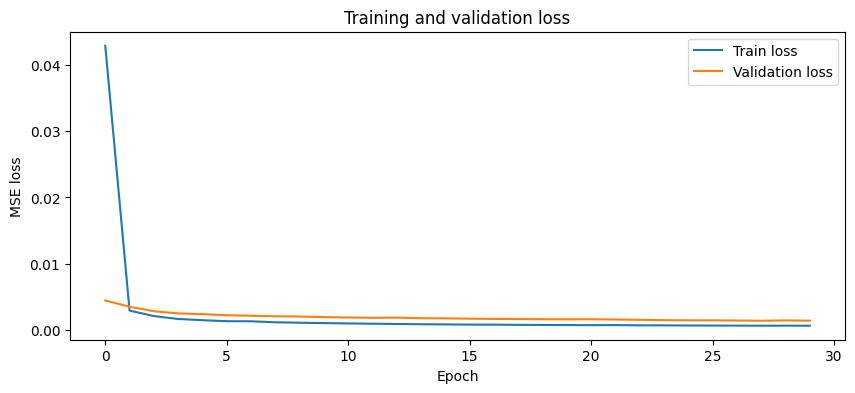

In [ ]:
m3 = build_model(W, X_tr_n.shape[2])
m3.summary()

es3 = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = m3.fit(X_tr_n, X_tr_n,
                 epochs=30, batch_size=128,
                 validation_data=(X_va_n, X_va_n),
                 callbacks=[es3], verbose=1)

plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epoch')
plt.ylabel('MSE loss')
plt.legend()
plt.show()

## 8. Evaluation on unseen test data

This cell measures how well the model separates normal from abnormal windows on the **test set**, which was never used for training or for choosing the threshold.

- **AUC** summarises how well the error separates the two classes regardless of the threshold (0.5 = guessing, 1.0 = perfect).
- Two thresholds are chosen using the **validation set only**: (a) the 99th percentile of the error on normal validation windows, and (b) the value that gives the best F1-score on validation.
- For each threshold, the confusion matrix, precision, recall and F1-score are reported on the test set.

In [ ]:
va_err = get_err(m3, X_va)
te_err = get_err(m3, X_te)
print("Test AUC:", roc_auc_score(y_te, te_err))

thr_pct = np.percentile(va_err[y_va == 0], 99)

p, r, t = precision_recall_curve(y_va, va_err)
f1_curve = (2 * p * r / (p + r + 1e-9))[:-1]
thr_f1 = t[np.argmax(f1_curve)]

for name, thr in [("99th percentile of normal validation error", thr_pct),
                  ("best F1 on validation", thr_f1)]:
    y_pred = (te_err > thr).astype(int)
    print(f"\n=== Threshold: {name} = {thr:.4f} ===")
    print(confusion_matrix(y_te, y_pred))
    print(classification_report(y_te, y_pred, target_names=['Normal', 'Abnormal'], digits=2))

Test AUC: 0.986505957548062

=== Threshold: 99th percentile of normal validation error = 0.0780 ===
[[15731   724]
 [   46  1337]]
              precision    recall  f1-score   support

      Normal       1.00      0.96      0.98     16455
    Abnormal       0.65      0.97      0.78      1383

    accuracy                           0.96     17838
   macro avg       0.82      0.96      0.88     17838
weighted avg       0.97      0.96      0.96     17838


=== Threshold: best F1 on validation = 0.0804 ===
[[15769   686]
 [   68  1315]]
              precision    recall  f1-score   support

      Normal       1.00      0.96      0.98     16455
    Abnormal       0.66      0.95      0.78      1383

    accuracy                           0.96     17838
   macro avg       0.83      0.95      0.88     17838
weighted avg       0.97      0.96      0.96     17838



### 8.1 Reconstruction error on the test set

This plot shows the reconstruction error of the test windows, coloured by their true label, together with the chosen threshold. A good model keeps normal windows below the line and abnormal windows above it.

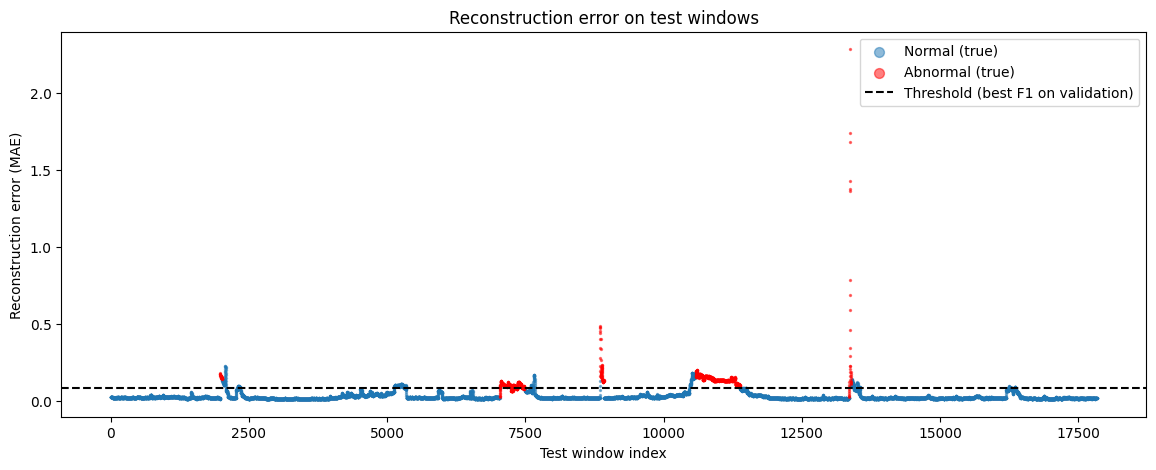

In [ ]:
plt.figure(figsize=(14, 5))
idx = np.arange(len(te_err))
plt.scatter(idx[y_te == 0], te_err[y_te == 0], s=2, label='Normal (true)', alpha=0.5)
plt.scatter(idx[y_te == 1], te_err[y_te == 1], s=2, label='Abnormal (true)', alpha=0.5, color='red')
plt.axhline(thr_f1, color='black', linestyle='--', label='Threshold (best F1 on validation)')
plt.title('Reconstruction error on test windows')
plt.xlabel('Test window index')
plt.ylabel('Reconstruction error (MAE)')
plt.legend(markerscale=5)
plt.show()

## 9. Saving the model

The trained model is saved in the native Keras format (`.keras`, the recommended replacement for the legacy `.h5` format) to Google Drive. The chosen threshold is saved next to it, because the model is only useful together with its threshold.

In [ ]:
save_dir = '/content/drive/MyDrive/ML_Project/'
m3.save(save_dir + 'industrial_pump_lstm_autoencoder.keras')
np.save(save_dir + 'threshold_best_f1.npy', np.array([thr_f1]))
print("Saved model and threshold to", save_dir)

Saved model and threshold to /content/drive/MyDrive/ML_Project/


## 10. Results summary and limitations

*(Fill in after the final run.)*

| Metric (abnormal class, test set) | Baseline | Improved |
|---|---|---|
| Precision | 0.08 | |
| Recall | 0.99 | |
| F1-score | | |
| AUC | | |

**Limitations**
- Block splitting mixes time periods between train and test. It handles drift in normal behaviour, but it does not simulate predicting the *future* strictly.
- The dataset has very few BROKEN events, so the model cannot be evaluated separately for real breakdowns.
- Results depend on the window length (30) and the threshold rule.

**Future work:** compare with simpler baselines (for example Isolation Forest), tune the window length, and test strict time-ordered evaluation on new data.